# Beyond the Stopwatch: What 10 Hz Combine Tracking Adds — and What It Does Not — to Draft Evaluation

**NFL Big Data Bowl 2027 · University Track · Team `dewang2025` (solo)**

Companion Notebook to the writeup of the same title (see `notes/writeup_draft.md` in the
[GitHub repo](https://github.com/wangde2021-collab/kaggle/tree/main/03-nfl-big-data-bowl)).
All analysis code lives in that repo (`src/`, MIT licence); this Notebook wires it up on
Kaggle, verifies the frozen headline results, and regenerates every figure.

**Headline findings (frozen, Gemini round-5 reviewed, seed 42):**
- **Double dissociation** — draft pick buys snaps, not per-play efficiency. Tracking adds
  nothing to snap volume (Y1 hurdle AUC Δ +0.0009; stage-2 r Δ −0.0005) but lifts per-play
  quality (Y2 r 0.1009 → 0.1335, Δ +0.0326).
- **Beyond the stopwatch** — the four static tests predict nothing for per-play quality
  (r = −0.0016); tracking stacked on them reaches r = 0.0755 (Δ +0.0771, 95% CI
  [+0.0122, +0.1545]).
- **Honest boundary** — tracking cannot beat draft pick + official NGS composite
  (Δ −0.0006, 95% CI [−0.0169, +0.0158]).
- **One feature survives everything** — skill-drill peak speed (skill_s_peak): β = +0.156,
  q = 0.004; still β = +0.138, p = 0.0027 after the NGS final score.

**Data:** NFL Big Data Bowl 2027 competition data (CC BY-NC 4.0, attached below as the
competition dataset — not redistributed). 510 players, 2023–2025 draft classes;
Y2 n = 299 (≥75 regular-season plays).


## How to reproduce

Two paths, same code (`src/`, frozen after Gemini round-5 review):

| Path | What runs | Time |
|---|---|---|
| **A. Verify (this Notebook, default)** | Load the frozen `phase3_results` JSON, print the headline table, regenerate all 7 figures | seconds |
| **B. Smoke chain** | `features_combine` (small-drill mode) → `targets` → `game_kinematics` → `model_phase3 --quick` | ~30–60 min |
| **C. Full rerun** | Set `RUN_FULL = True` and run the pipeline cells: ETL → features → targets → game kinematics → `model_phase3 --within-year` | ~6 h on 2 vCPUs |

Path C is deterministic (seed 42) and reproduces the frozen numbers exactly. It is **not**
executed in this published Notebook — the full run is single-core-bound and takes hours —
but every command is present and runnable. Do not re-run Path C just to view results; use Path A.


## 0. Setup — locate the repo and the data

On Kaggle this Notebook clones the public repo itself (pipeline code + frozen
results live there) and expects the competition dataset attached (it mounts at
`/kaggle/input/nfl-big-data-bowl-2027/`). Locally it uses the project directory.
Nothing here downloads raw competition data.


In [1]:
import os, sys, subprocess

# Set True to reproduce the full pipeline from scratch (~6 h on 2 vCPUs).
# Default False: this Notebook only verifies the frozen results (seconds).
RUN_FULL = False

KAGGLE_REPO = "/kaggle/working/kaggle/03-nfl-big-data-bowl"
LOCAL_REPO = os.path.expanduser("~/workspace/kaggle-data/03-nfl-big-data-bowl")

# On Kaggle, clone the public repo (pipeline code + frozen results live there;
# this Notebook ships only the narrative, the checks, and the embedded outputs).
# Requires internet enabled on the kernel (set in kernel metadata).
if os.path.isdir("/kaggle/working"):
    if not os.path.exists(os.path.join(KAGGLE_REPO, "src", "model_phase3.py")):
        print("cloning public repo ...")
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/wangde2021-collab/kaggle.git",
                        "/kaggle/working/kaggle"], check=True)
REPO = KAGGLE_REPO if os.path.exists(os.path.join(KAGGLE_REPO, "src", "model_phase3.py")) \
    else LOCAL_REPO
print("REPO =", REPO)
print("RUN_FULL =", RUN_FULL)
os.chdir(REPO)
print("cwd =", os.getcwd())


REPO = /home/hatch/workspace/kaggle-data/03-nfl-big-data-bowl
RUN_FULL = False
cwd = /home/hatch/workspace/kaggle-data/03-nfl-big-data-bowl


## 1. Attach the competition data (Kaggle only)

On Kaggle, link the attached competition CSVs into `data/` (symlinks — the 2.3 GB of
tracking files are not copied). Locally this cell is a no-op: the data are already in place.


In [2]:
import glob

KAGGLE_INPUT = "/kaggle/input/nfl-big-data-bowl-2027"
DATA_DIR = os.path.join(REPO, "data")
if os.path.isdir(KAGGLE_INPUT):
    os.makedirs(DATA_DIR, exist_ok=True)
    for src in sorted(glob.glob(os.path.join(KAGGLE_INPUT, "*.csv"))):
        dst = os.path.join(DATA_DIR, os.path.basename(src))
        if not os.path.exists(dst):
            os.symlink(src, dst)
            print("linked", os.path.basename(src))
        else:
            print("exists", os.path.basename(src))
else:
    print("not on Kaggle (no /kaggle/input) — using local data/ as-is")
    print("data files:", len(glob.glob(os.path.join(DATA_DIR, "*.csv"))))


not on Kaggle (no /kaggle/input) — using local data/ as-is
data files: 9


## 2. Verify the frozen headline results (Path A)

Reads the frozen server result file — the single source of truth — and prints the
headline numbers. If any of these differ from the writeup, the writeup is wrong, not the JSON.


In [3]:
import json

J = json.load(open("notes/phase3_results_round5_server.json"))
y2 = J["Y2_quality"]
y1h = J["Y1_hurdle_stage1"]
y1s = J["Y1_stage2_logASR"]

def show(label, d):
    print(f"{label:38s} r={d['metric_mean']:.4f}")

print(f"seed={J['seed']}  {J['n_repeats']}x5 CV  perm={J['n_perm']}  boot={J['n_boot']}  "
      f"within-year={J['within_year_harmonization']}")
print("\nY1 (snap volume, n=510) — tracking adds nothing:")
show("  M0a (draft pick) hurdle AUC", y1h["M0a"])
show("  M1  (tracking)    hurdle AUC", y1h["M1"])
print(f"  delta hurdle: {y1h['delta_M1_vs_M0a']['mean']:+.4f} "
      f"CI {y1h['delta_M1_vs_M0a']['ci95']}")
show("  M0a stage-2 log snaps r", y1s["M0a"])
show("  M1  stage-2 log snaps r", y1s["M1"])
print(f"  delta stage-2: {y1s['delta_M1_vs_M0a']['mean']:+.4f} "
      f"CI {y1s['delta_M1_vs_M0a']['ci95']}")

print("\nY2 (per-play quality, n=299) — tracking adds signal:")
for m in ["M0b_stopwatch", "M1_over_stopwatch", "M1_track_only", "M0a",
          "M1a", "M1", "M0c_ngs", "M0all", "M1_over_all"]:
    show(f"  {m}", y2[m])
for k in ["delta_M1_over_stopwatch_vs_M0b_stopwatch",
          "delta_M1_track_only_vs_M0b_stopwatch",
          "delta_M1a_vs_M0a", "delta_M1_vs_M0a", "delta_M1_over_all_vs_M0all"]:
    v = y2[k]
    print(f"  {k}: {v['mean']:+.4f} CI [{v['ci95'][0]:+.4f}, {v['ci95'][1]:+.4f}]")
print(f"  permutation (M1 vs M0a): obs {y2['permutation']['obs_delta']:+.4f}, "
      f"p = {y2['permutation']['p_perm']:.4f}")
print(f"  Y2 R2: {y2['r2_M0a']:.4f} (pick) -> {y2['r2_M1']:.4f} (M1)")

lad = J["robustness_skill_s_peak_ladder"]
print("\nskill_s_peak robustness ladder:")
for i, s in enumerate(lad, 1):
    sub = f" [{s['subset']}]" if s['subset'] else ""
    print(f"  step {i}: {s['controls']}{sub} n={s['n']} "
          f"beta={s['beta']:+.4f} p={s['p']:.4g}")


seed=42  10x5 CV  perm=1000  boot=2000  within-year=True

Y1 (snap volume, n=510) — tracking adds nothing:
  M0a (draft pick) hurdle AUC          r=0.8631
  M1  (tracking)    hurdle AUC         r=0.8641
  delta hurdle: +0.0009 CI [-0.007913813880342447, 0.006458196169409511]
  M0a stage-2 log snaps r              r=0.6611
  M1  stage-2 log snaps r              r=0.6607
  delta stage-2: -0.0005 CI [-0.001111954306650395, 0.00033258002770528985]

Y2 (per-play quality, n=299) — tracking adds signal:
  M0b_stopwatch                        r=-0.0016
  M1_over_stopwatch                    r=0.0755
  M1_track_only                        r=0.0902
  M0a                                  r=0.1009
  M1a                                  r=0.1403
  M1                                   r=0.1335
  M0c_ngs                              r=0.1984
  M0all                                r=0.1829
  M1_over_all                          r=0.1823
  delta_M1_over_stopwatch_vs_M0b_stopwatch: +0.0771 CI [+0.0122, 

## 3. Regenerate all figures (Path A)

Runs `notes/make_figures_phase4.py`, which reads only the frozen JSON and writes
`figures/fig1–fig7` (PNG + PDF) plus `figures/figure_data.json` with every plotted value.
`notes/verify_figures_phase4.py` independently re-checks all 285 plotted values against the JSON.


In [4]:
import subprocess

r = subprocess.run([sys.executable, "notes/make_figures_phase4.py"],
                   capture_output=True, text=True)
print(r.stdout[-1500:])
if r.returncode != 0:
    print(r.stderr[-3000:])
    raise SystemExit("figure script failed")
r = subprocess.run([sys.executable, "notes/verify_figures_phase4.py"],
                   capture_output=True, text=True)
print(r.stdout)
print(r.stderr[-2000:] if r.returncode != 0 else "")


wrote fig1_double_dissociation
wrote fig2_beyond_stopwatch
wrote fig3_dl_edge_idl
wrote fig4_pricing_efficiency
wrote fig5_loco_temporal
wrote fig6_robustness_ladder
wrote fig7_ktr_transfer
wrote figure_data.json
wrote notes/tables_phase4.md
DONE



checks=285 fails=0
ALL 285 CHECKS PASSED — figures+tables = 9 (< 10)




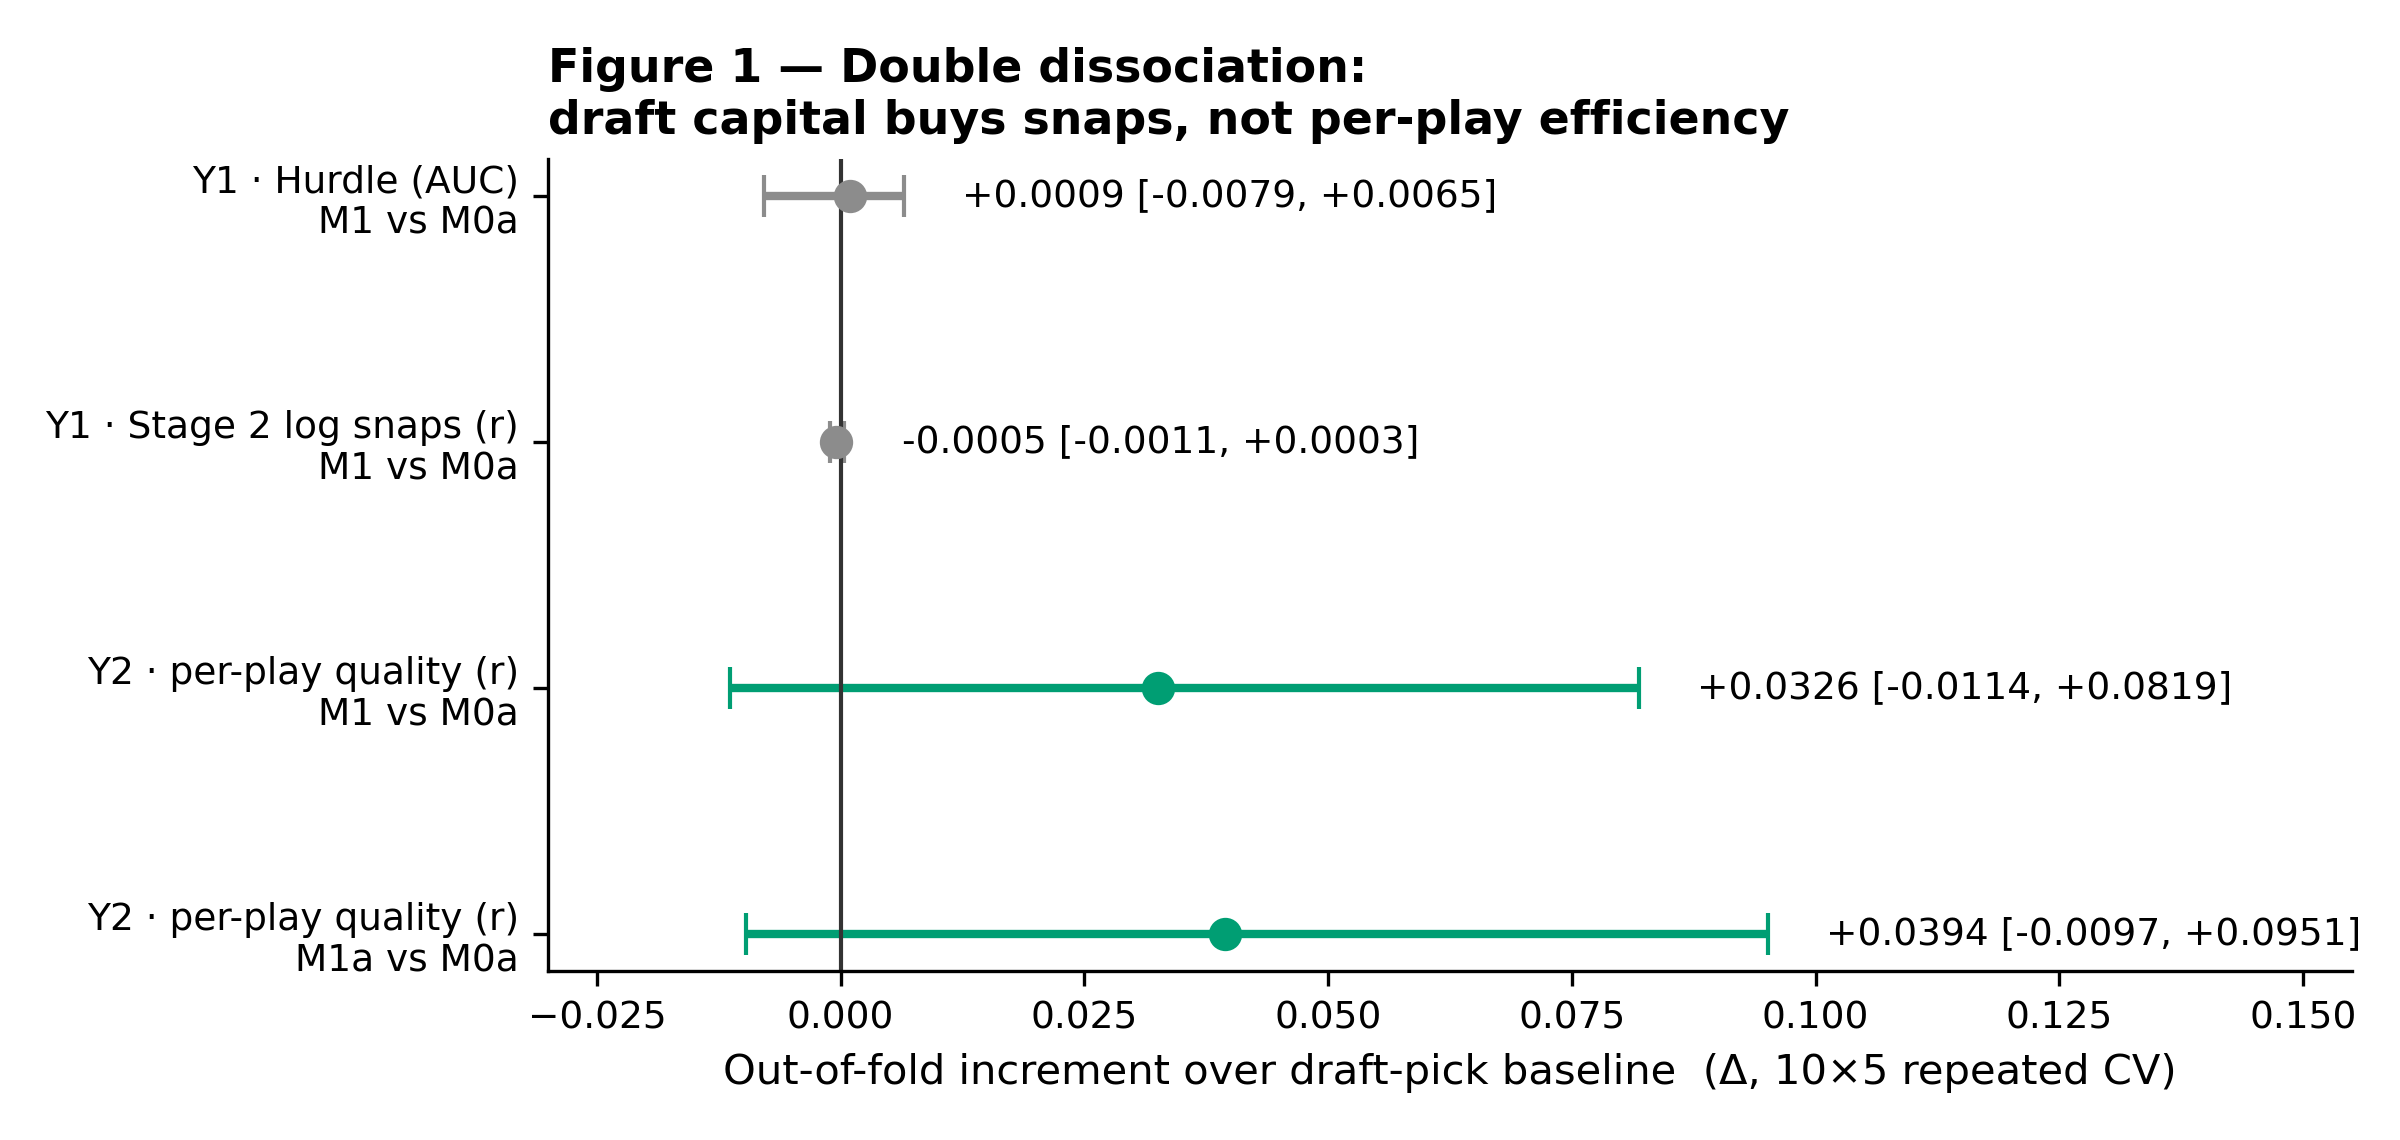

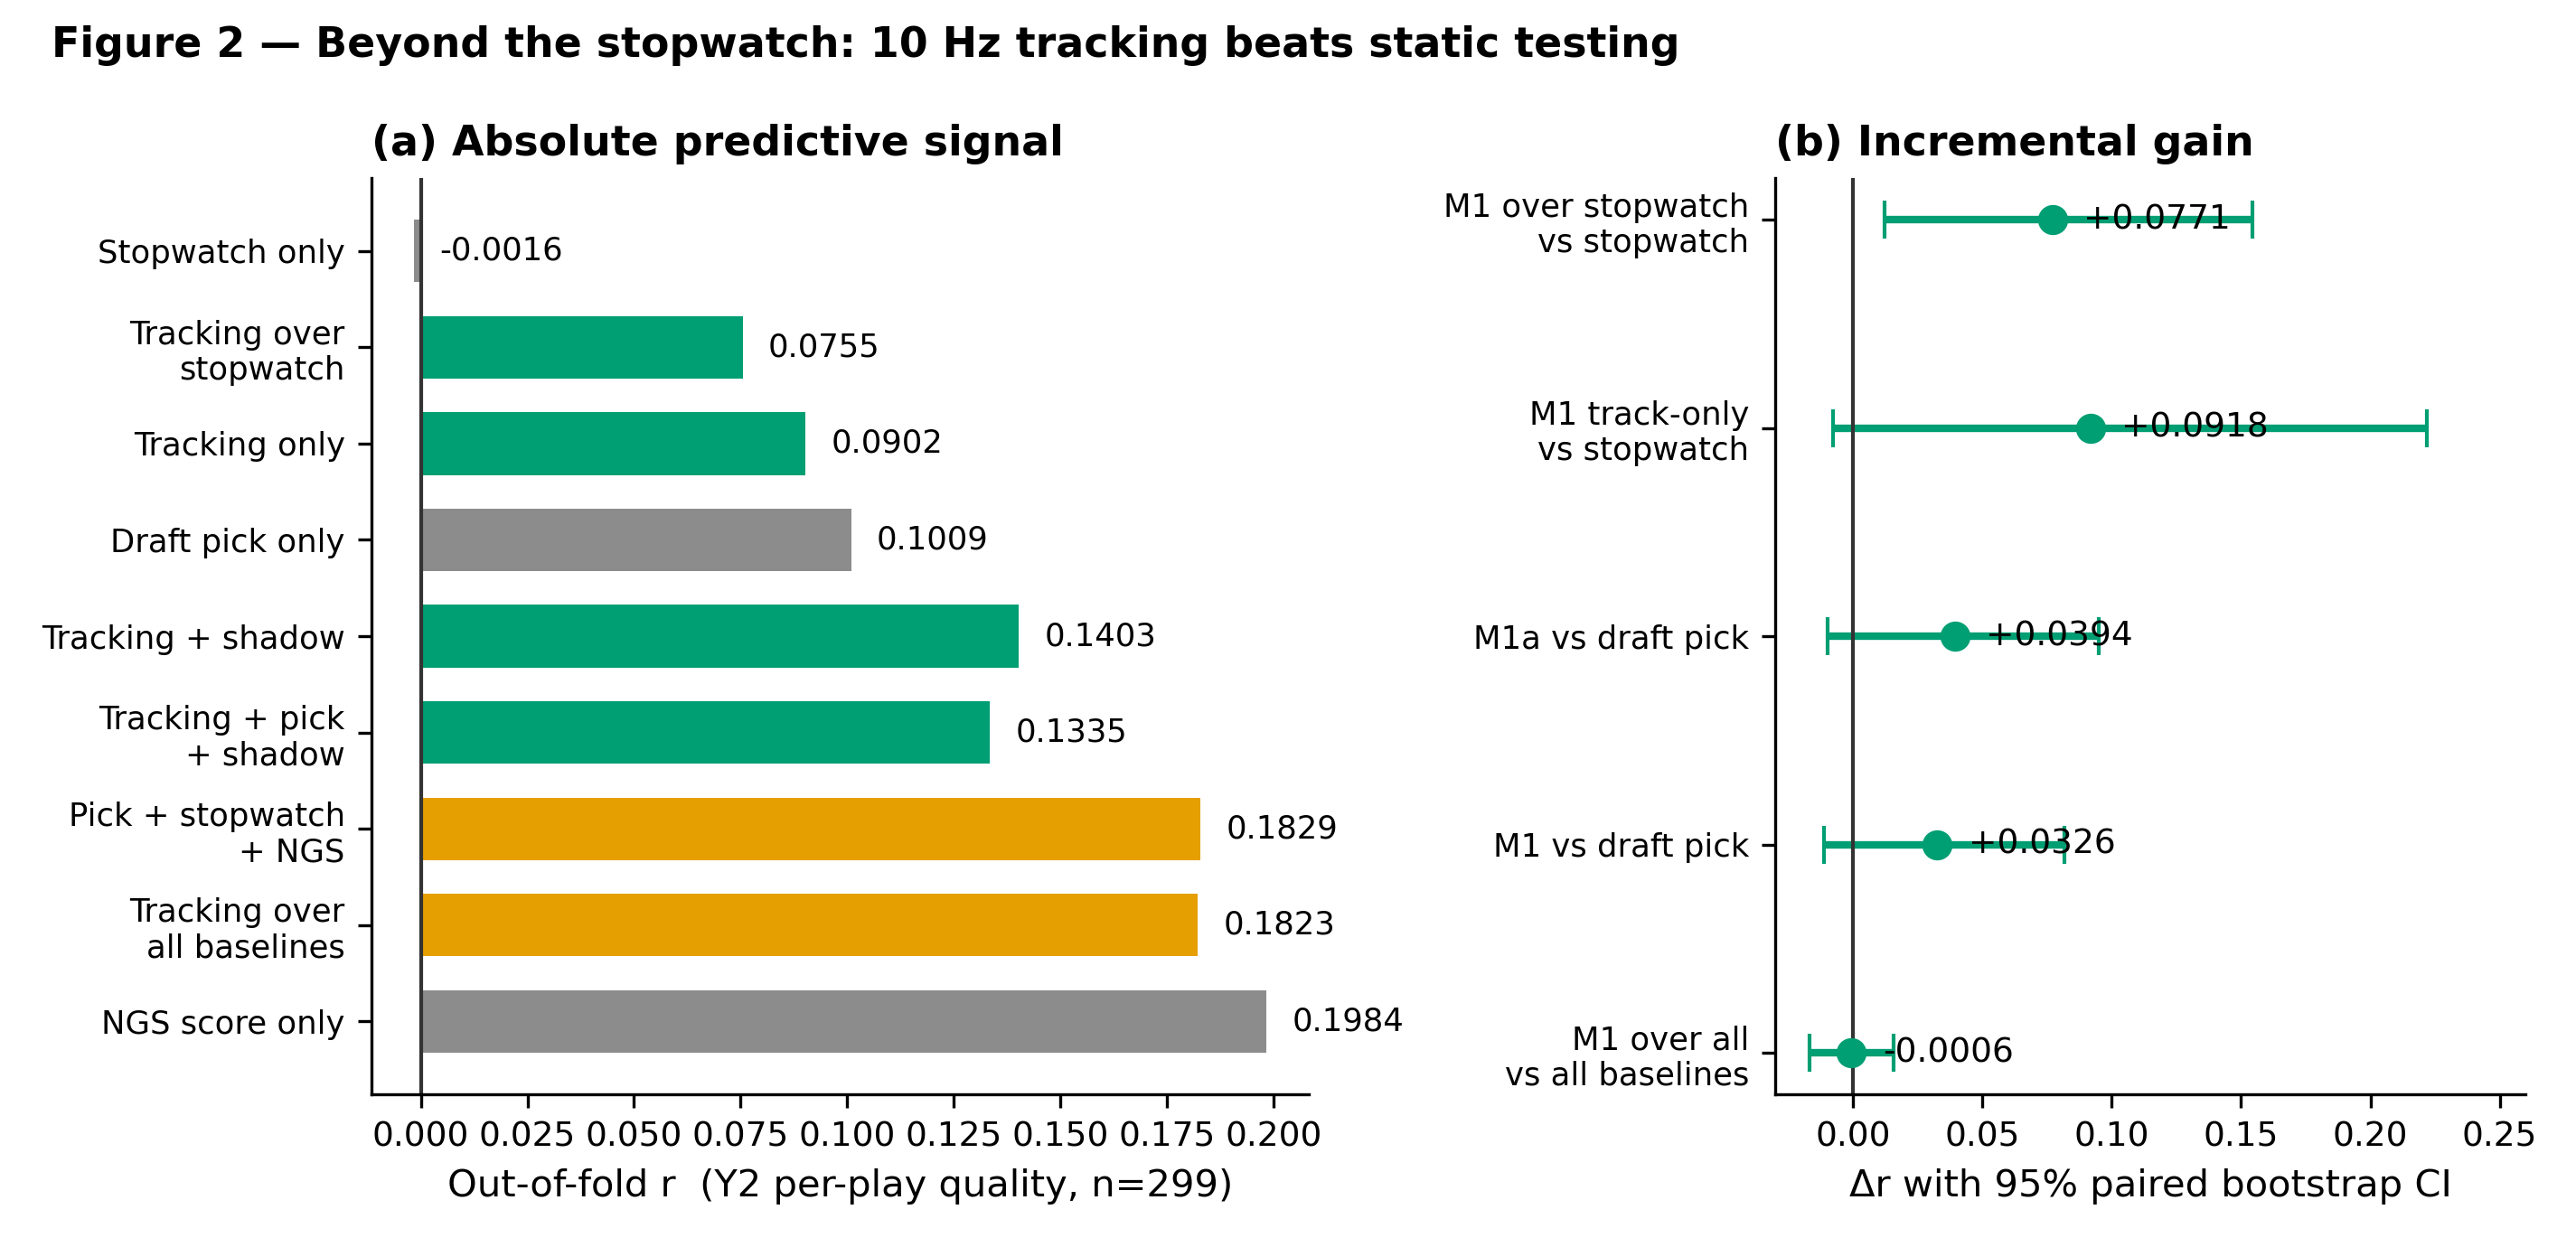

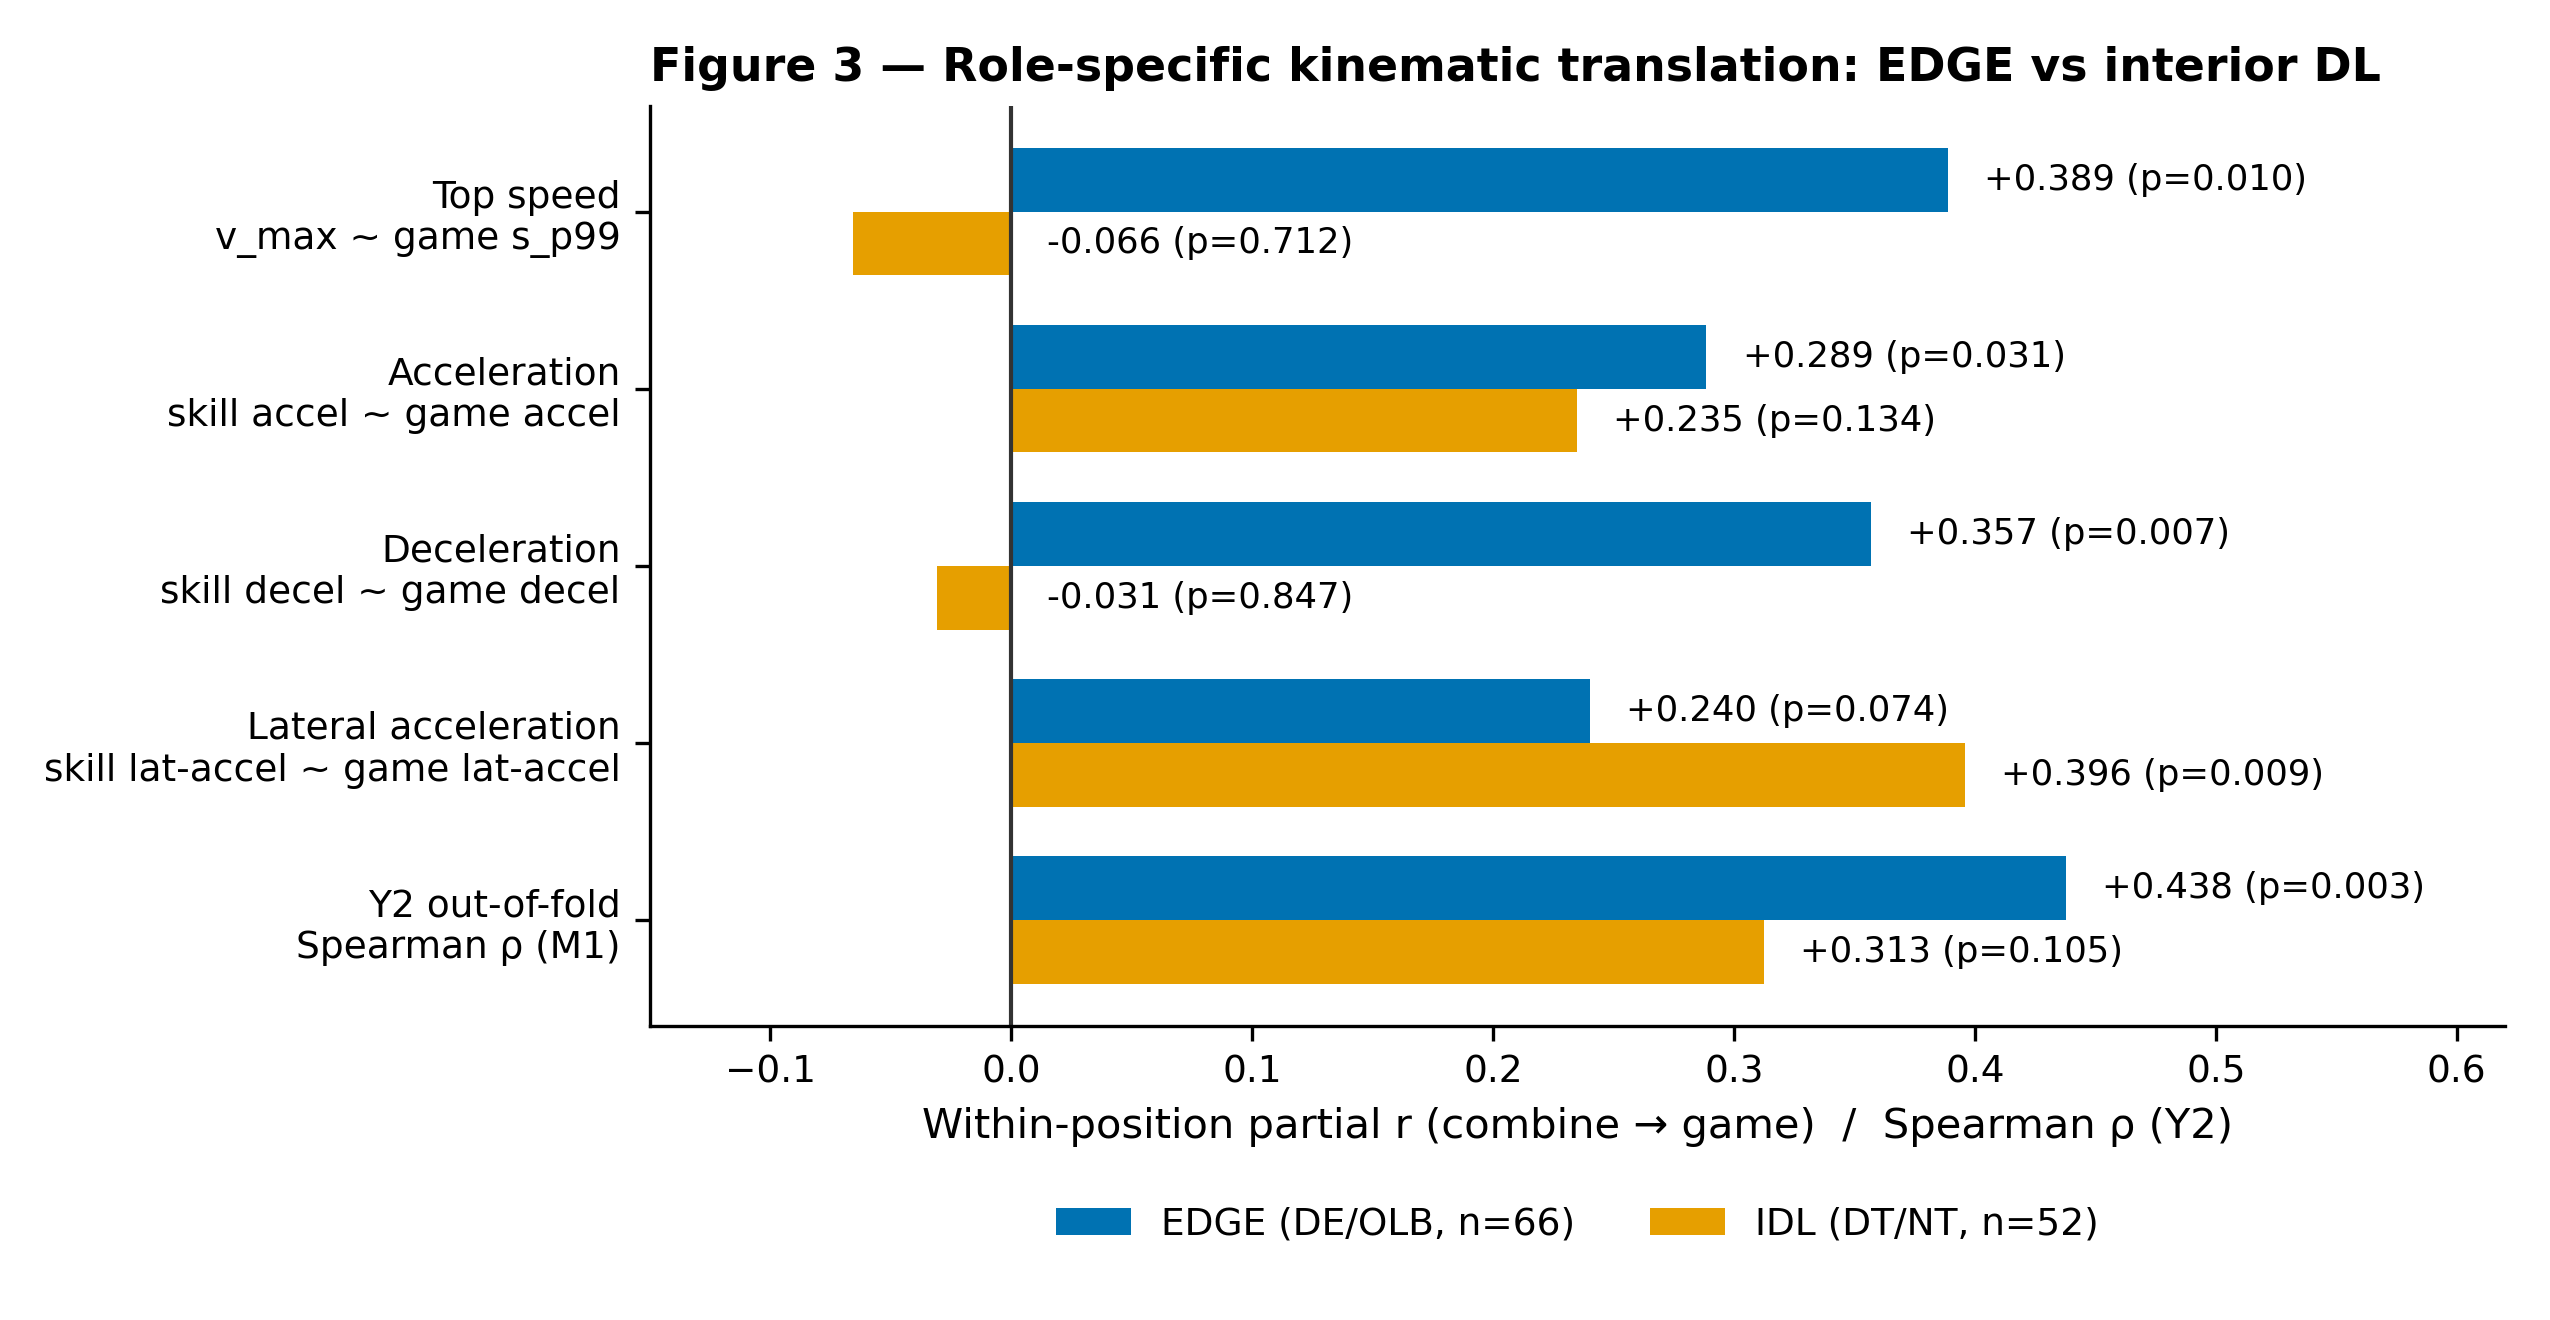

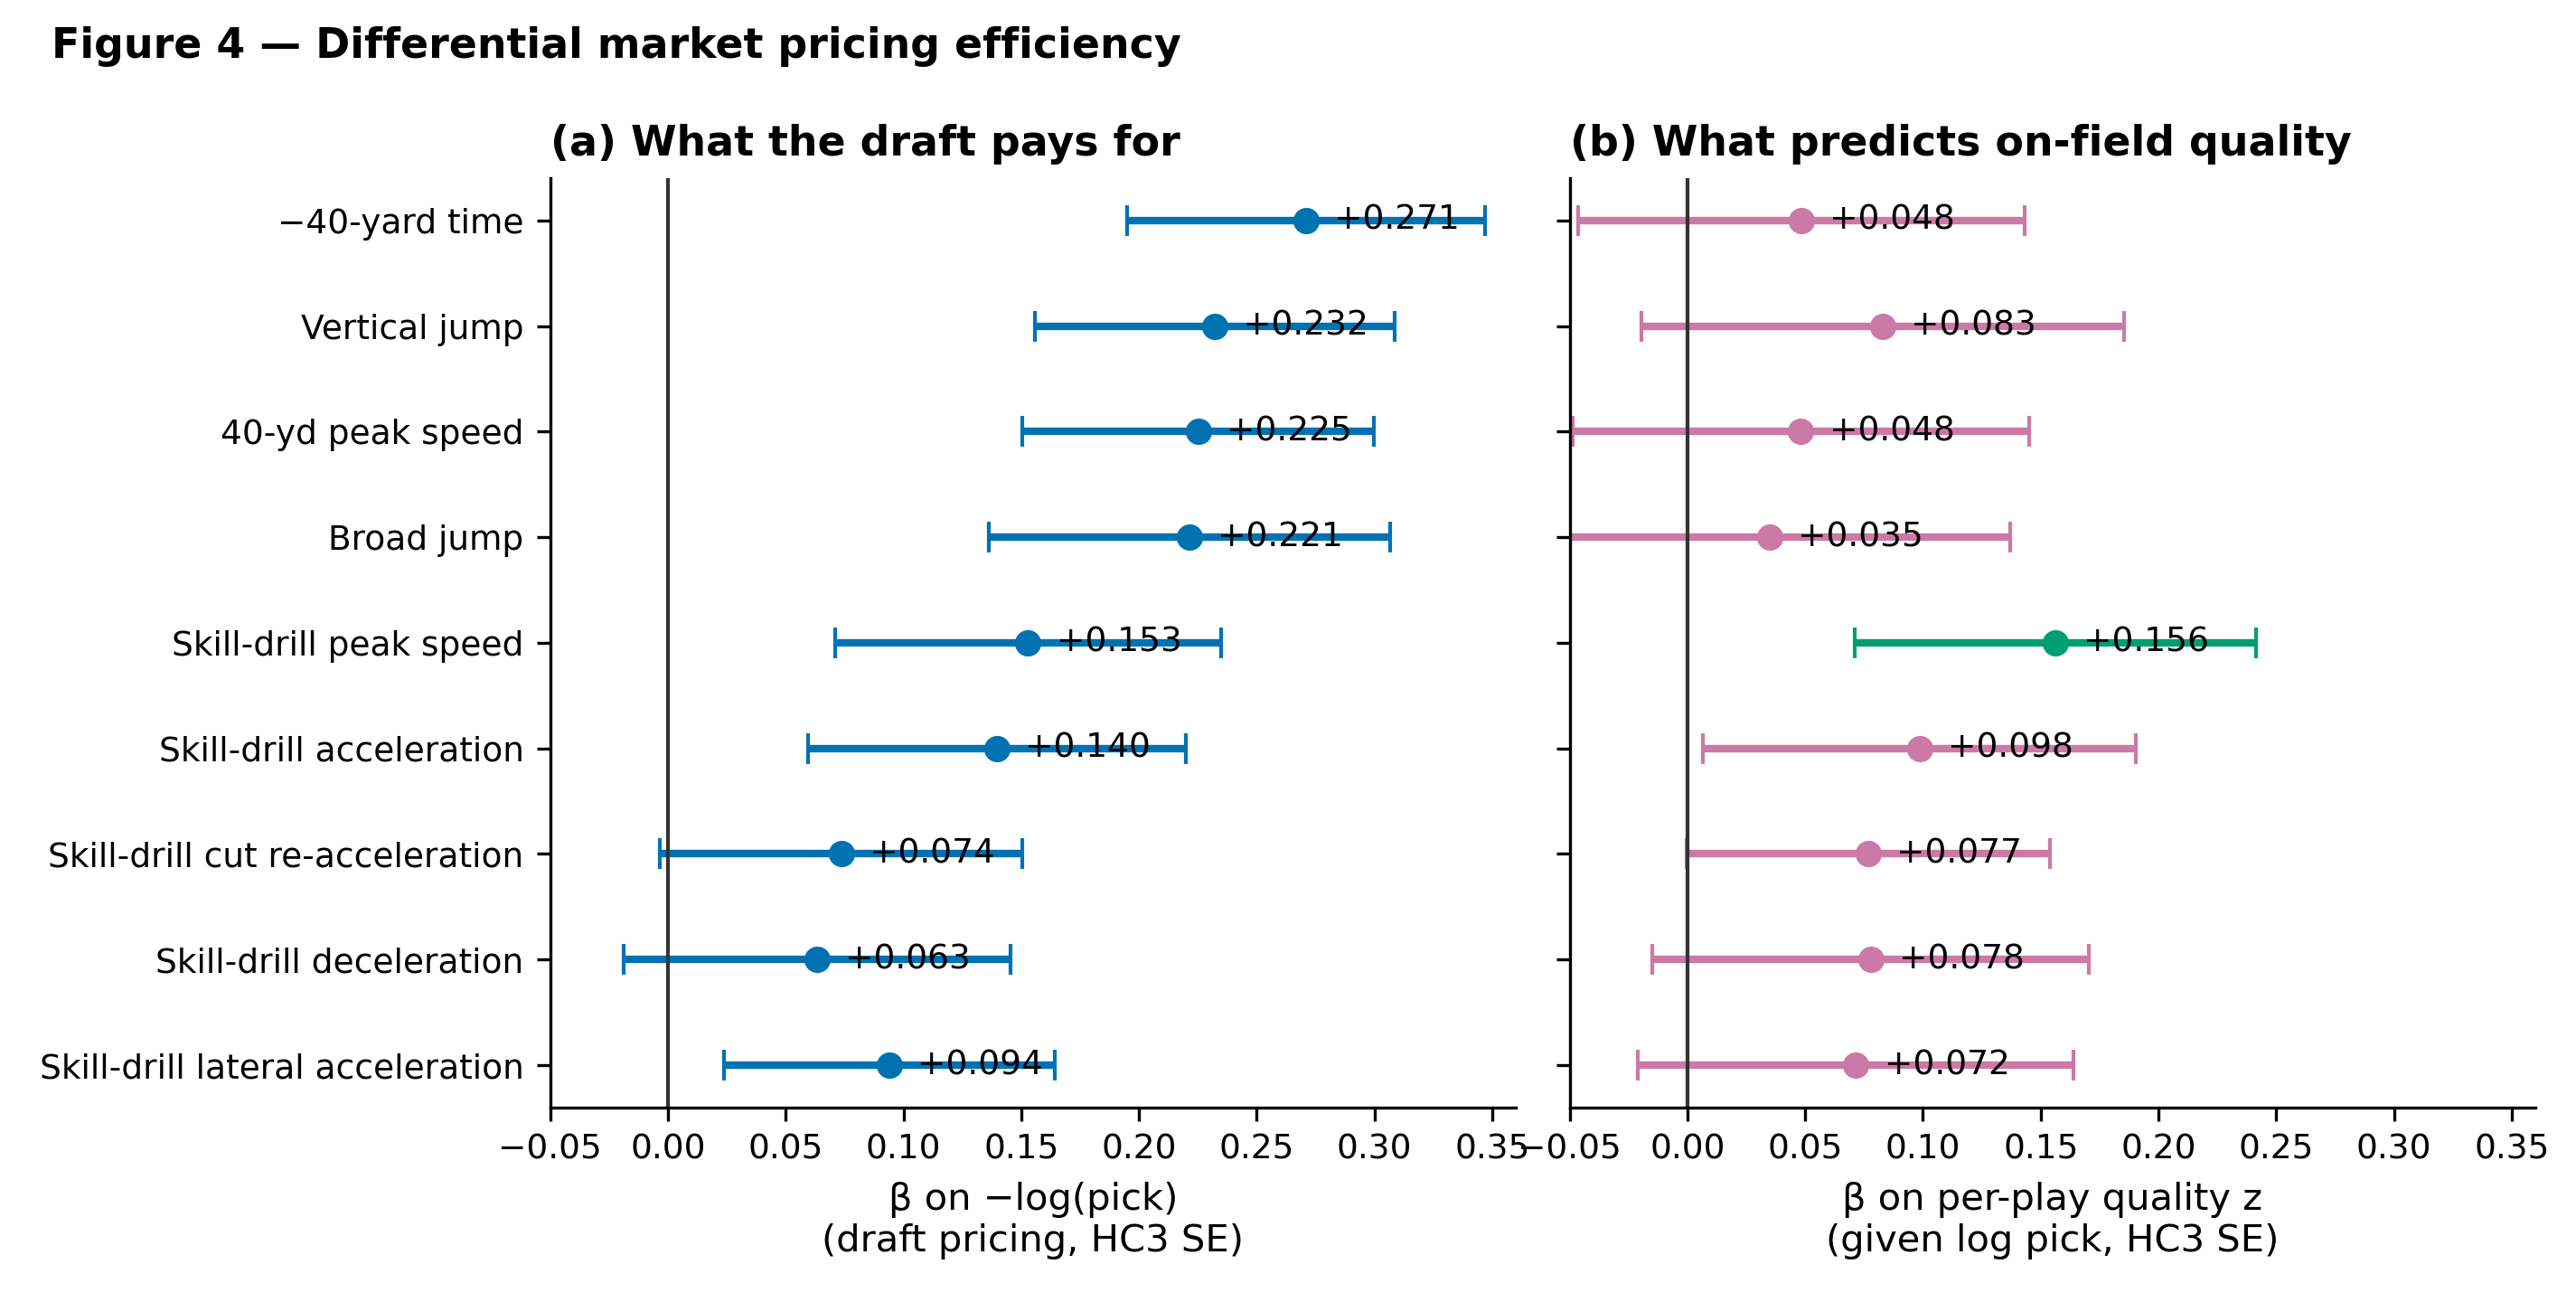

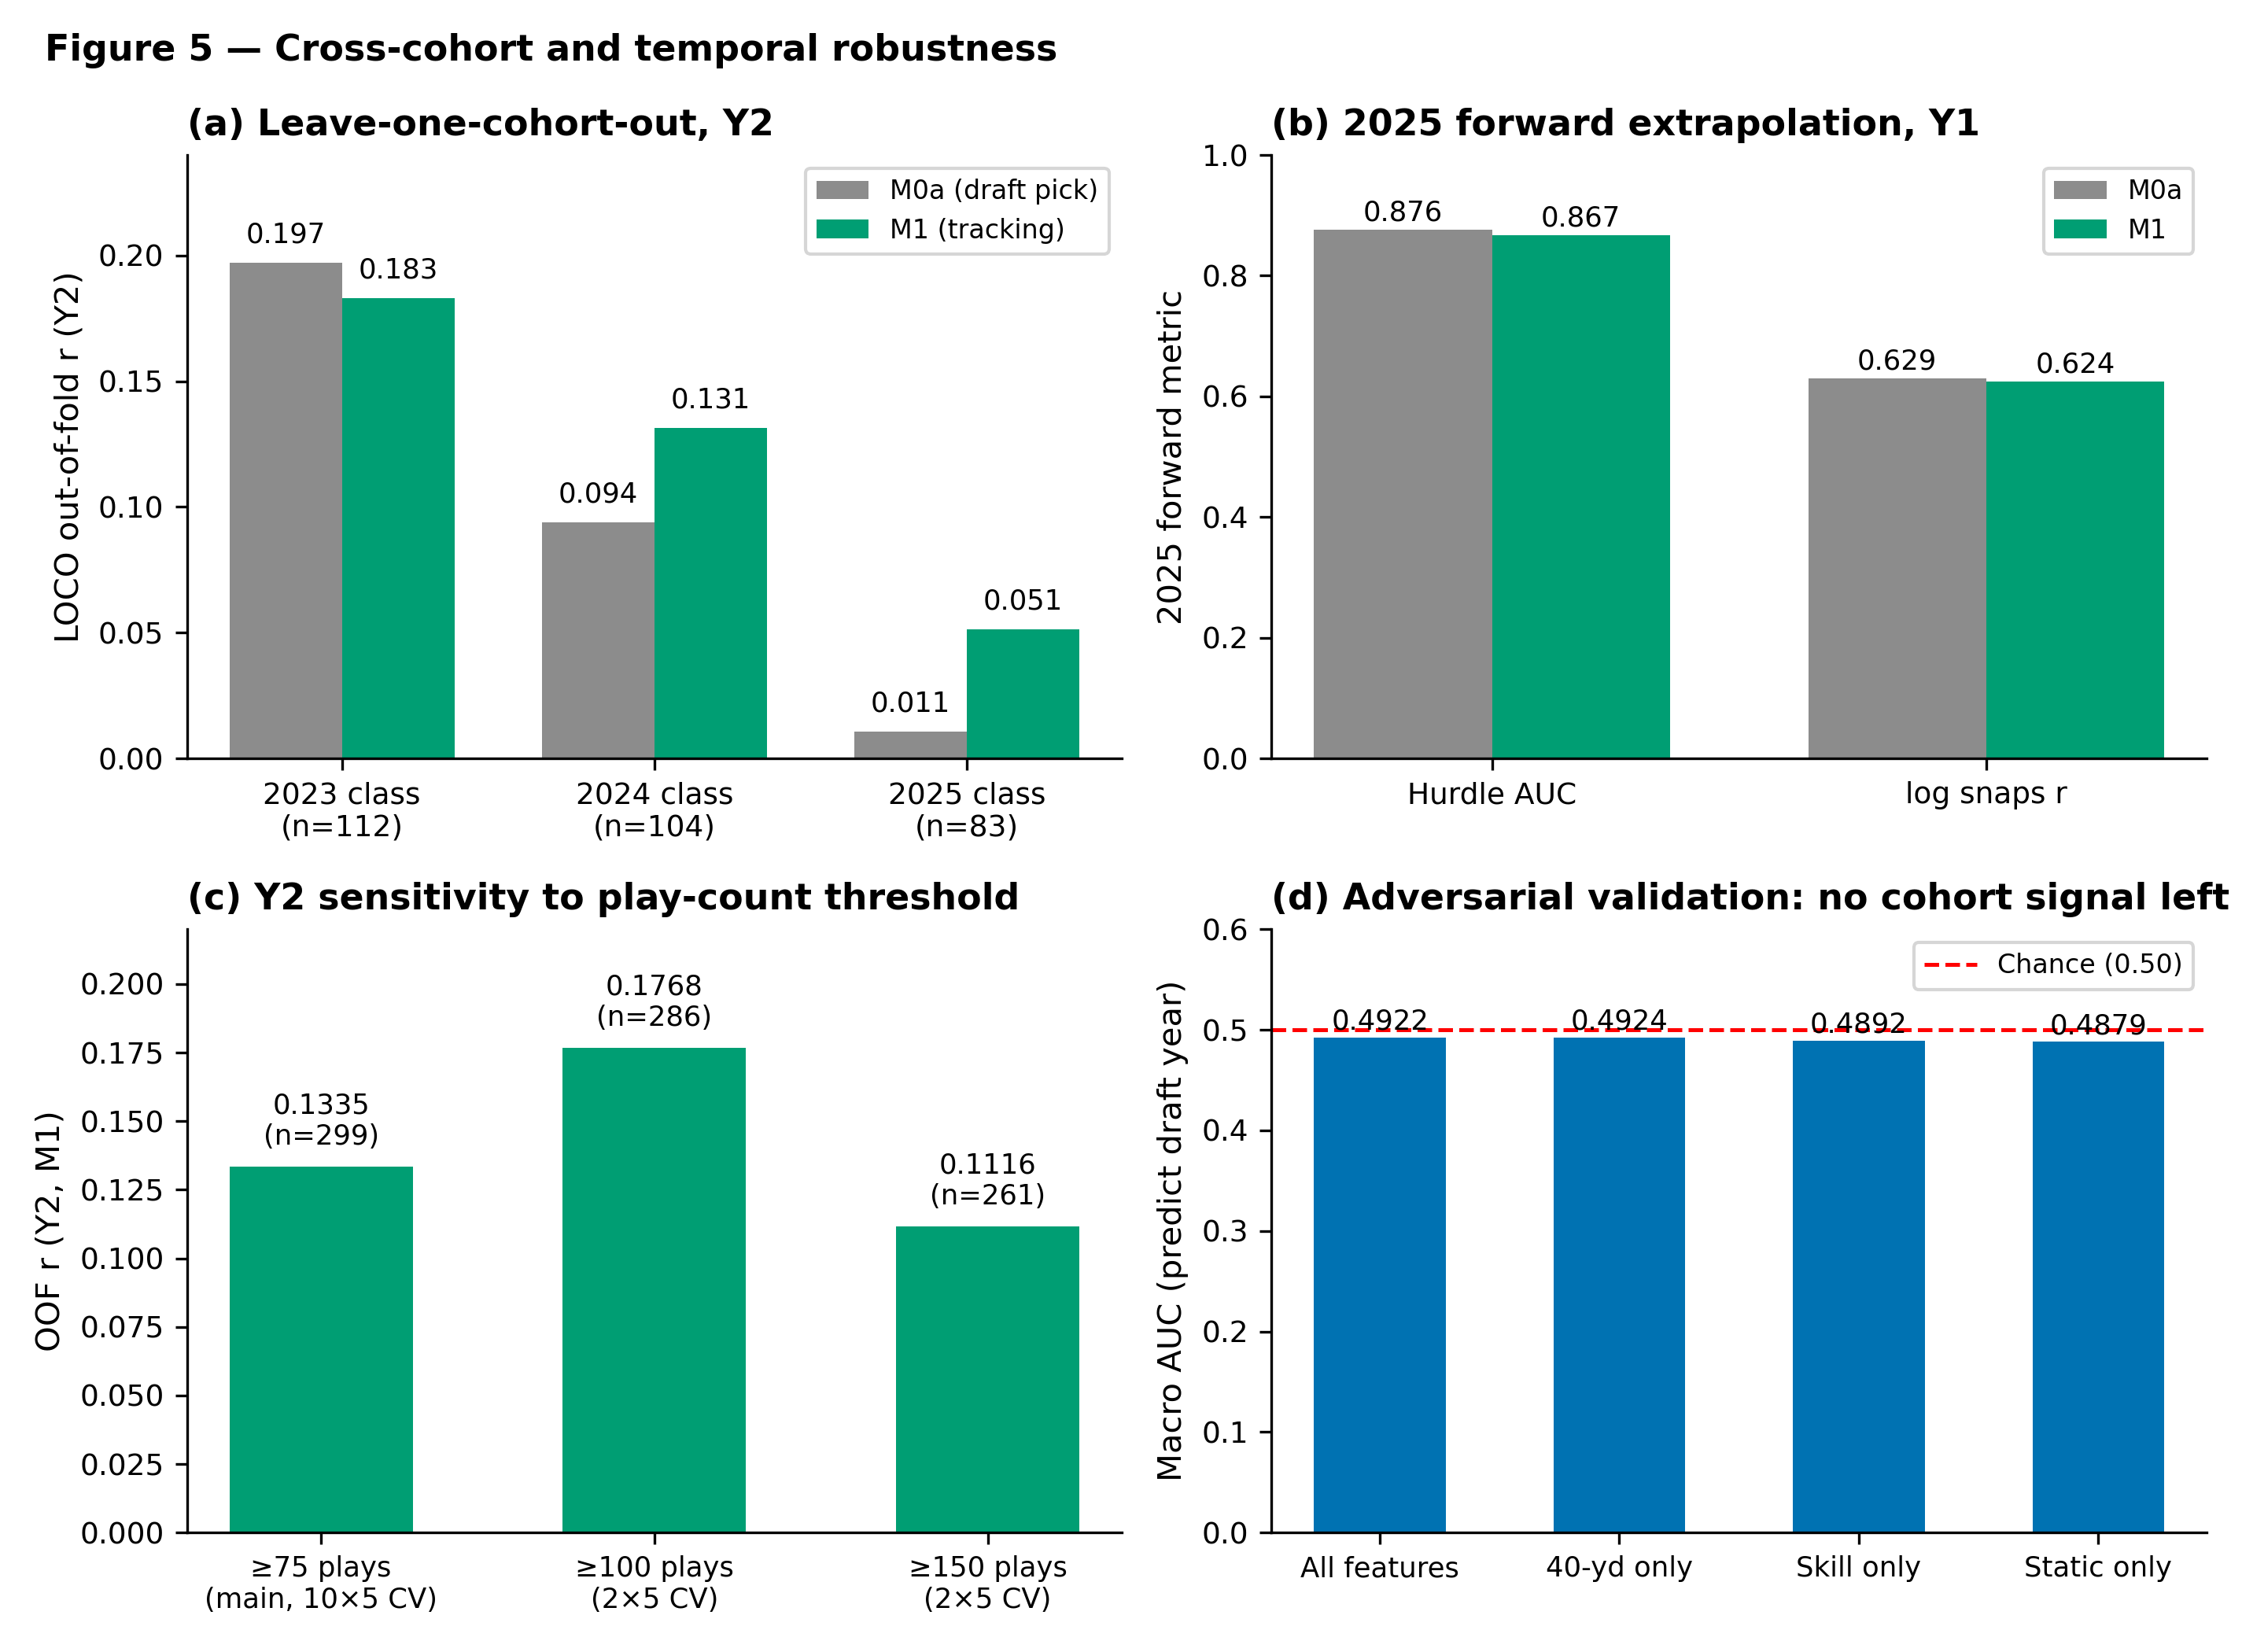

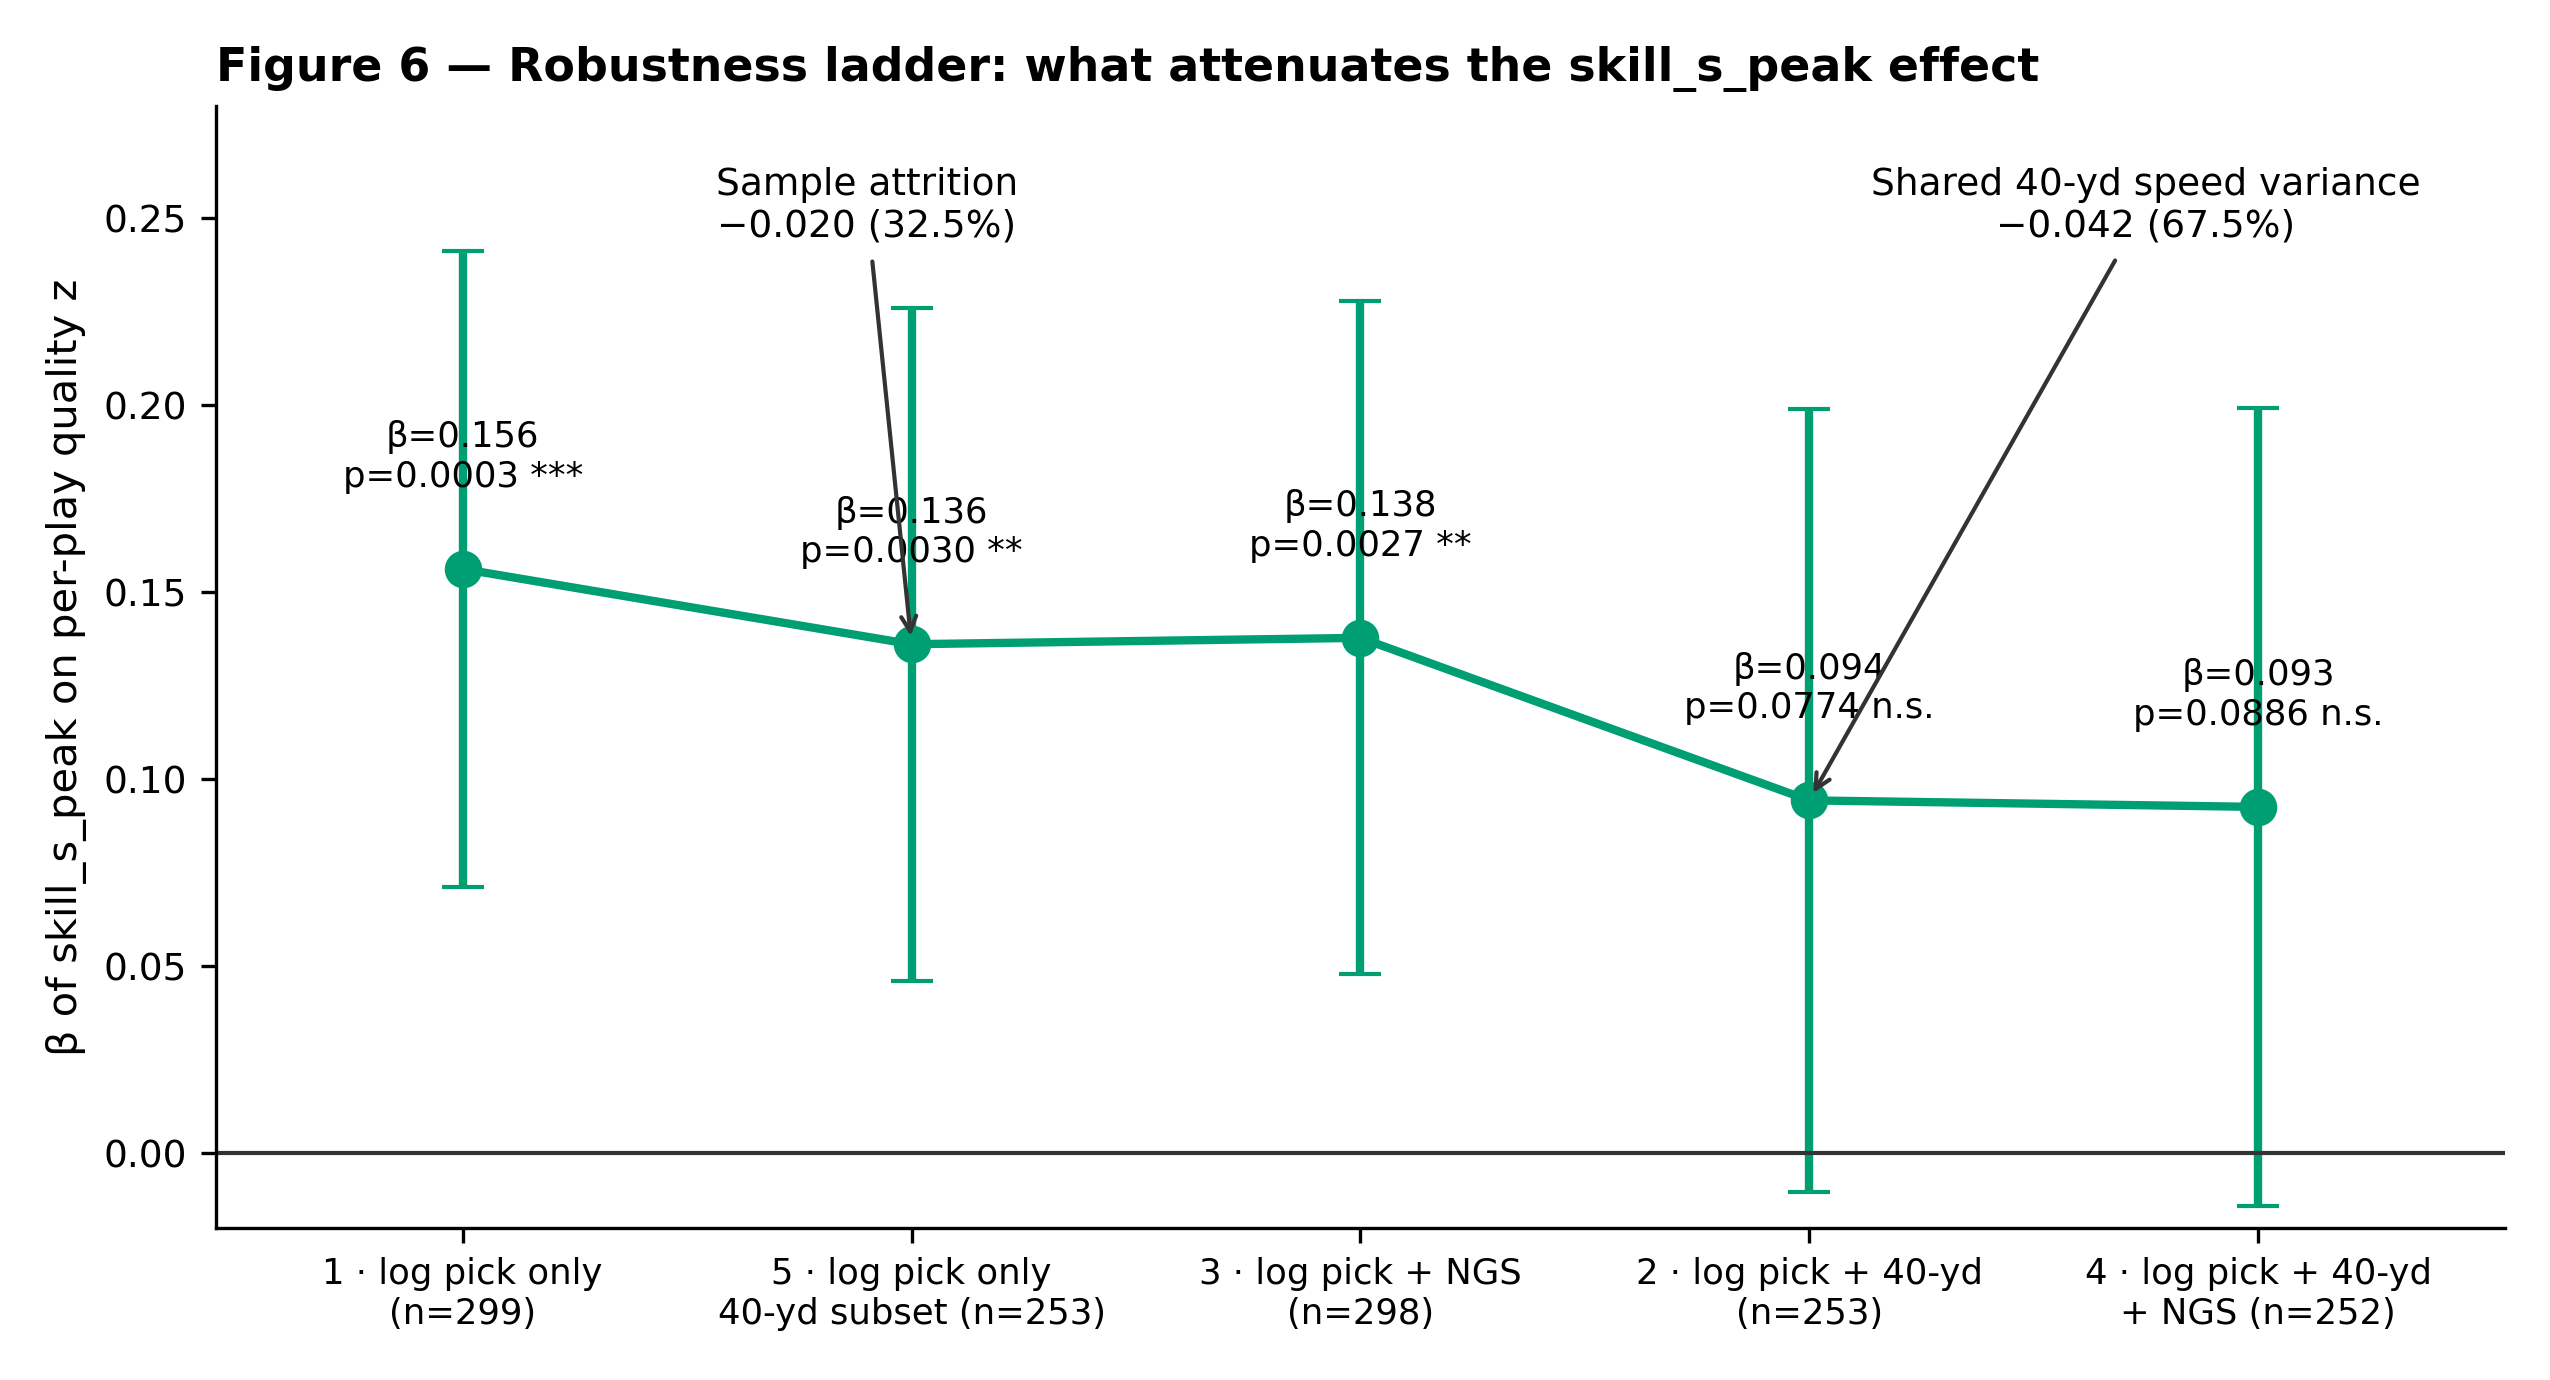

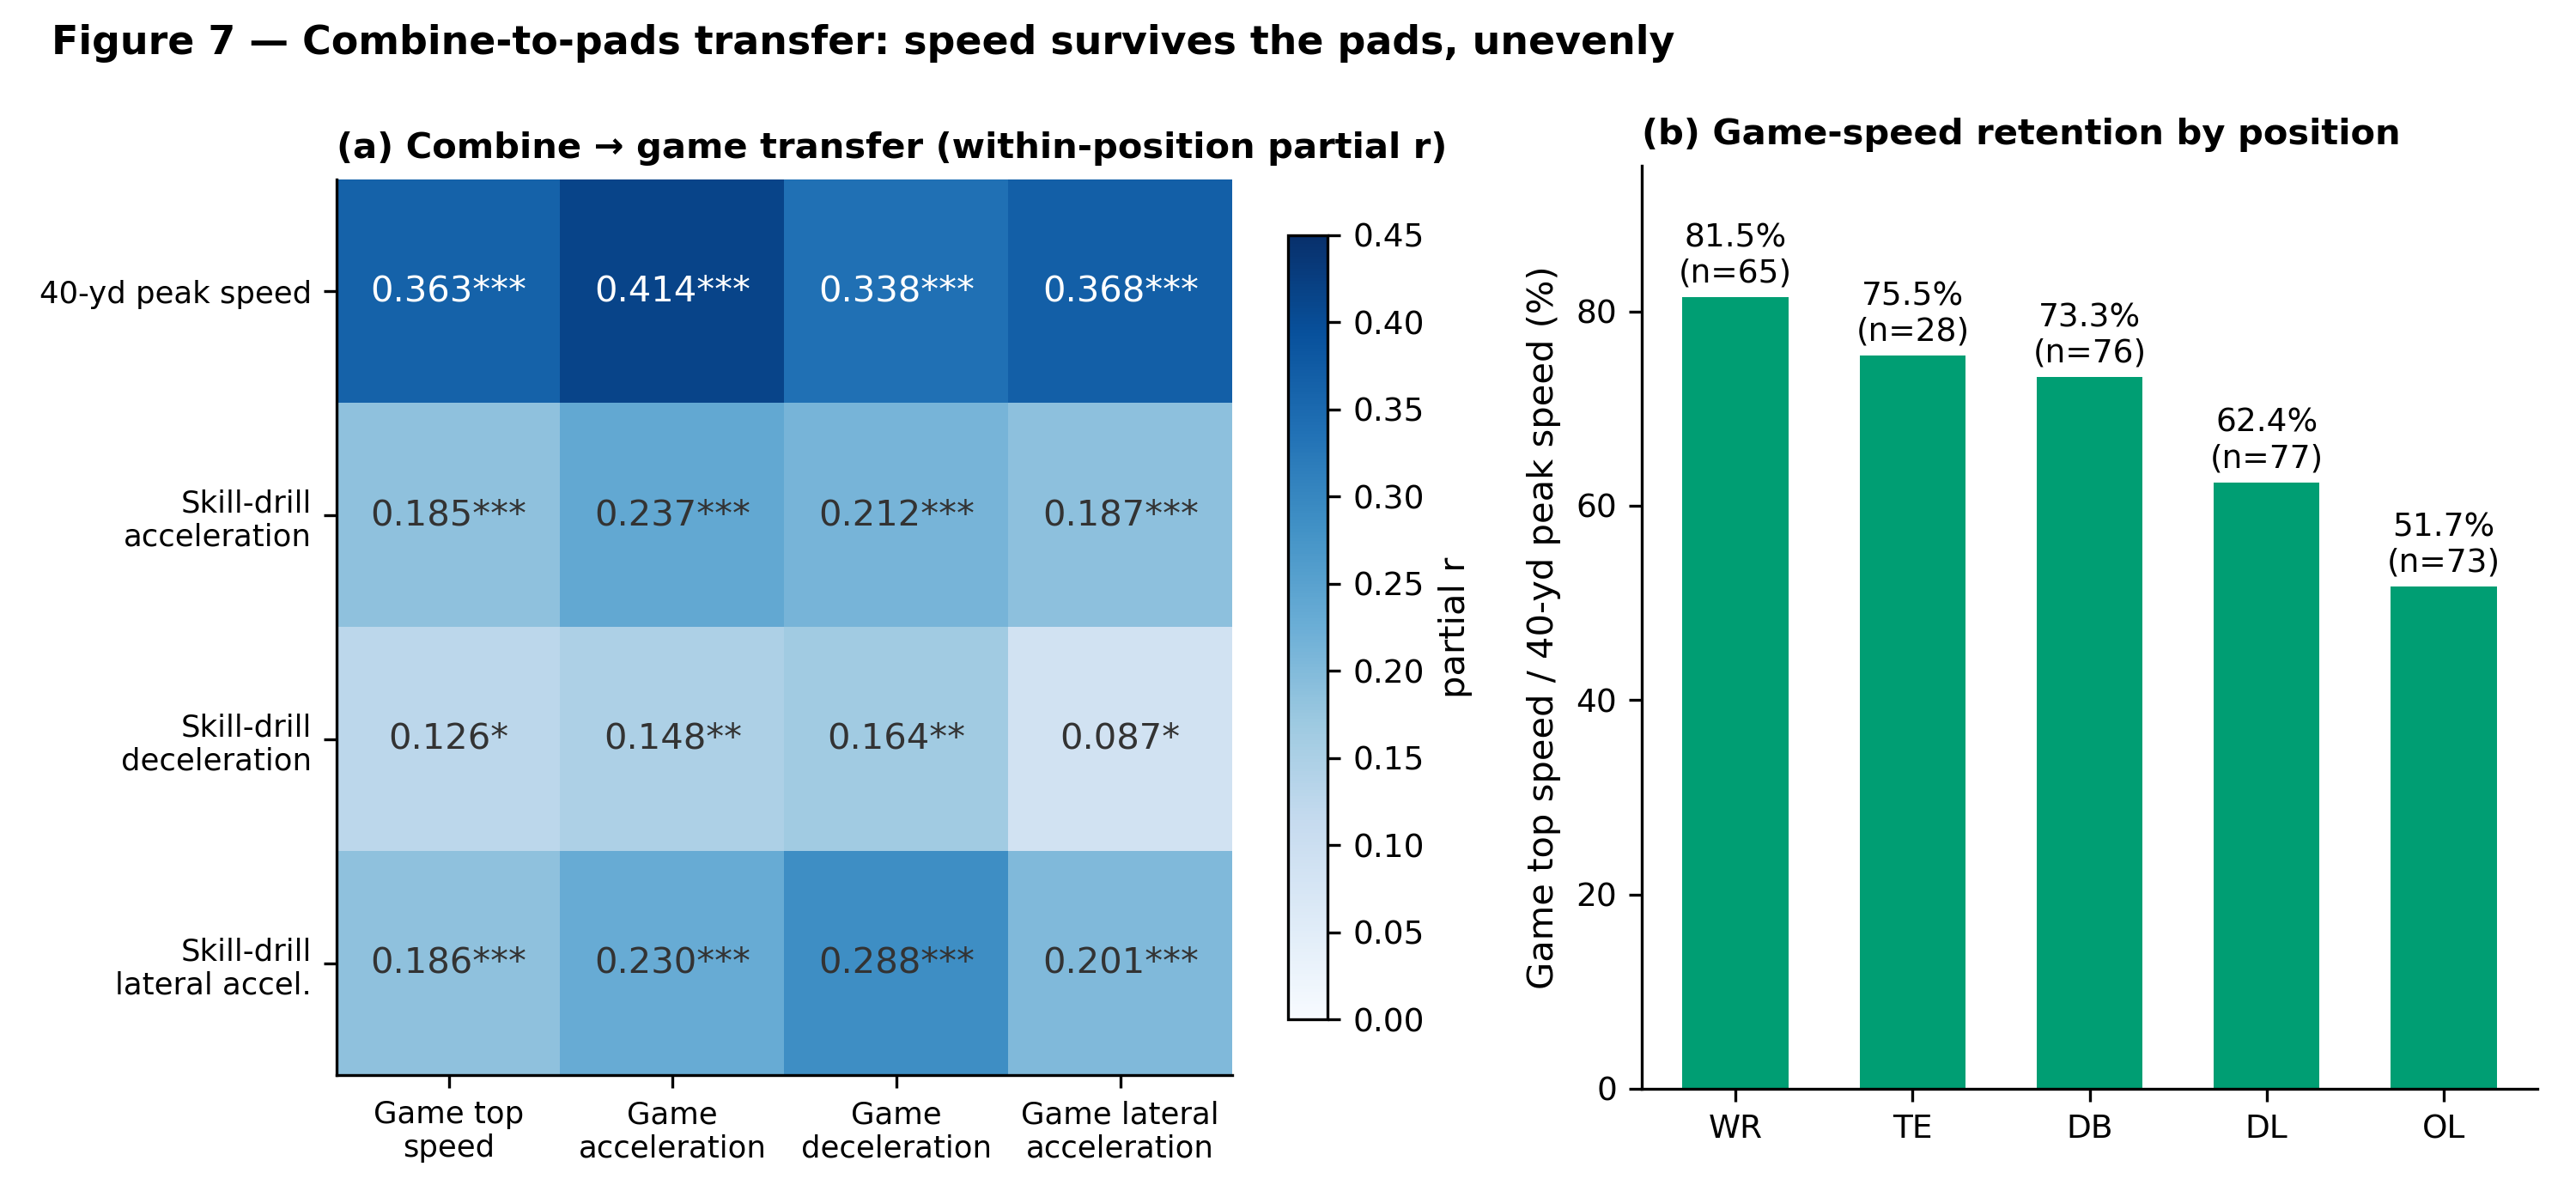

In [5]:
from IPython.display import Image, display

for name in ["fig1_double_dissociation", "fig2_beyond_stopwatch",
             "fig3_dl_edge_idl", "fig4_pricing_efficiency",
             "fig5_loco_temporal", "fig6_robustness_ladder",
             "fig7_ktr_transfer"]:
    display(Image(filename=f"figures/{name}.png", width=950))


## 4. Full pipeline from scratch (Path C — long-running, opt-in)

Each cell below runs one pipeline stage **only if `RUN_FULL` is True** (set it in the
setup cell). Leave it `False` to skip. Commands and defaults are exactly the frozen
ones (seed 42, `--within-year` harmonisation on, 10×5 CV, 1,000 permutations,
2,000 bootstraps). Expected runtimes are for a 2-vCPU machine; a 4-core Kaggle
session is faster on the single-threaded stages only marginally — the pipeline is
largely single-core by design, and the frozen numbers must not change, so do not
parallelise or retune anything.


In [6]:
import subprocess

if RUN_FULL:
    # Phase 1: CSV -> Parquet (REG filter, float32, player_play assertion).
    # ~15 min for 2.3 GB. Writes data/parquet/ + manifest.json.
    subprocess.run([sys.executable, "src/etl_parquet.py"], check=True)
else:
    print("skipped (RUN_FULL=False) — Phase 1 ETL")


skipped (RUN_FULL=False) — Phase 1 ETL


In [7]:
import subprocess

if RUN_FULL:
    # Phase 2: Combine features + Shadow Agility calibration (31 stable drills).
    # ~5 min. Writes data/derived/combine_features.parquet.
    subprocess.run([sys.executable, "src/features_combine.py",
                    "--min-drill-players", "20"], check=True)
else:
    print("skipped (RUN_FULL=False) — Phase 2 Combine features")


skipped (RUN_FULL=False) — Phase 2 Combine features


In [8]:
import subprocess

if RUN_FULL:
    # Phase 3a: targets — Y1 hurdle/stage-2, Y2 empirical-Bayes quality.
    # ~1 min. Writes data/derived/targets_summary.json.
    subprocess.run([sys.executable, "src/targets.py"], check=True)
else:
    print("skipped (RUN_FULL=False) — Phase 3a targets")


skipped (RUN_FULL=False) — Phase 3a targets


In [9]:
import subprocess

if RUN_FULL:
    # Phase 3b: regular-season game kinematics (10.4M frames, 401 players).
    # ~35 min. Writes data/derived/game_kinematics.parquet.
    subprocess.run([sys.executable, "src/game_kinematics.py"], check=True)
else:
    print("skipped (RUN_FULL=False) — Phase 3b game kinematics")


skipped (RUN_FULL=False) — Phase 3b game kinematics


In [10]:
import subprocess

if RUN_FULL:
    # Phase 3c: modelling — 10x5 CV, 1,000 permutations, 2,000 bootstraps.
    # ~5.8 h on 2 vCPUs. Writes logs/phase3_results.json + .md.
    # This is the frozen run; do not change flags, seed, or feature definitions.
    subprocess.run([sys.executable, "src/model_phase3.py", "--within-year"],
                   check=True)
else:
    print("skipped (RUN_FULL=False) — Phase 3c modelling (~5.8 h if enabled)")


skipped (RUN_FULL=False) — Phase 3c modelling (~5.8 h if enabled)


## 5. Smoke mode (Path B — quick end-to-end check)

Runs the same four stages on a small-drill subset with `--quick` (reduced CV
repeats). It validates that the code runs — it does **not** reproduce the frozen
numbers. Expected ~30–60 min. Set `RUN_SMOKE = True` to run it.


In [11]:
import subprocess

RUN_SMOKE = False
if RUN_SMOKE:
    subprocess.run([sys.executable, "src/features_combine.py",
                    "--min-drill-players", "3"], check=True)
    subprocess.run([sys.executable, "src/targets.py"], check=True)
    subprocess.run([sys.executable, "src/game_kinematics.py"], check=True)
    subprocess.run([sys.executable, "src/model_phase3.py", "--quick"], check=True)
else:
    print("skipped (RUN_SMOKE=False) — smoke chain")


skipped (RUN_SMOKE=False) — smoke chain


## Reproducibility notes

- **Frozen after Gemini round-5 review (2026-11-22):** Phase 1–3 code, features, and
  results are frozen. Do not change model hyperparameters or feature definitions.
- **Determinism:** seed 42 everywhere; the full run reproduces the frozen JSON exactly.
- **Runtime:** full pipeline ≈ 5.8 h on a 2-vCPU machine (model stage dominates;
  the permutation cache is exact memoisation — Stage 1 is provably permutation-invariant).
- **Licences:** code MIT; competition data CC BY-NC 4.0, non-commercial, not redistributed.
- **Writeup:** `notes/writeup_draft.md` in the repo (≤2,000 words, 7 figures + 2 tables).
- **No submission is made from this Notebook.** The competition allows one team
  submission; it requires separate approval.
